In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
plt.style.use('seaborn-v0_8-whitegrid')

DATA_PATH = "data/online_retail_II.csv"

df = pd.read_csv(DATA_PATH, encoding="latin1")

print(f"Dataset Shape: {df.shape}")
df.head()

Dataset Shape: (541910, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/10 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/10 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/10 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/10 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/10 8:26,3.39,17850.0,United Kingdom


In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541910 entries, 0 to 541909
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   Invoice      541910 non-null  str    
 1   StockCode    541910 non-null  str    
 2   Description  540456 non-null  str    
 3   Quantity     541910 non-null  int64  
 4   InvoiceDate  541910 non-null  str    
 5   Price        541910 non-null  float64
 6   Customer ID  406830 non-null  float64
 7   Country      541910 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB


In [16]:
df.describe()

,Quantity,Price,Customer ID
count,541910.000000,541910.000000,406830.000000
mean,9.552234,4.611138,15287.684160
std,218.080957,96.759765,1713.603074
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [19]:
df.isnull().sum()

Invoice             0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
Price               0
Customer ID    135080
Country             0
dtype: int64

In [44]:
pct = (df['Customer ID'].isnull().sum()/len(df))*100
print(f'percentage of null values in Customer ID = {pct:.2f}')

percentage of null values in Customer ID = 24.93


In [58]:
# Drop rows where Customer ID is missing
df.dropna(subset=['Customer ID'], inplace=True)

df['Customer ID'] = df['Customer ID'].astype(int)


In [38]:
df.isnull().sum()

Invoice        0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
Price          0
Customer ID    0
Country        0
dtype: int64

In [39]:
print("Shape after dropping null IDs:", df.shape)
df.head()

Shape after dropping null IDs: (406830, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/10 8:26,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/10 8:26,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/10 8:26,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/10 8:26,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/10 8:26,3.39,17850,United Kingdom


In [59]:
# Inspect invoices starting with 'C'
cancellations = df[df['Invoice'].astype(str).str.startswith('C')]
print("Total cancellation records:", len(cancellations))
cancellations.head()

Total cancellation records: 8905


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
141,C536379,D,Discount,-1,12/1/10 9:41,27.50,14527,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,12/1/10 9:49,4.65,15311,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,12/1/10 10:24,1.65,17548,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,12/1/10 10:24,0.29,17548,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,12/1/10 10:24,0.29,17548,United Kingdom


In [29]:
cancellations[['Quantity', 'Price']].describe()

,Quantity,Price
count,8905.000000,8905.000000
mean,-30.859966,18.845519
std,1170.154939,444.366043
min,-80995.000000,0.010000
25%,-6.000000,1.450000
50%,-2.000000,2.950000
75%,-1.000000,4.950000
max,-1.000000,38970.000000


In [61]:
df = df[~df['Invoice'].astype(str).str.startswith('C')]



In [67]:
df[df['Quantity'] <= 0].shape[0]

0

In [69]:
df[['Quantity', 'Price']].describe()

,Quantity,Price
count,397925.000000,397925.000000
mean,13.021793,3.116212
std,180.419984,22.096773
min,1.000000,0.000000
25%,2.000000,1.250000
50%,6.000000,1.950000
75%,12.000000,3.750000
max,80995.000000,8142.750000


In [70]:
zero_price_items = df[df['Price'] <= 0]
print("Count of items with Price <= 0:", len(zero_price_items))
zero_price_items.head()

Count of items with Price <= 0: 40


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
9302,537197,22841,ROUND CAKE TIN VINTAGE GREEN,1,12/5/10 14:02,0.0,12647,Germany
33576,539263,22580,ADVENT CALENDAR GINGHAM SACK,4,12/16/10 14:36,0.0,16560,United Kingdom
40089,539722,22423,REGENCY CAKESTAND 3 TIER,10,12/21/10 13:45,0.0,14911,EIRE
47068,540372,22090,PAPER BUNTING RETROSPOT,24,1/6/11 16:41,0.0,13081,United Kingdom
47070,540372,22553,PLASTERS IN TIN SKULLS,24,1/6/11 16:41,0.0,13081,United Kingdom


In [71]:
df = df[df['Price'] > 0]

df['Price'].describe()

count    397885.000000
mean          3.116525
std          22.097861
min           0.001000
25%           1.250000
50%           1.950000
75%           3.750000
max        8142.750000
Name: Price, dtype: float64

In [ ]:
df['Country'].value_counts().head(10)

Country
United Kingdom    354321
Germany             9040
France              8342
EIRE                7236
Spain               2484
Netherlands         2359
Belgium             2031
Switzerland         1841
Portugal            1462
Australia           1182
Name: count, dtype: int64

In [73]:
df['Description'] = df['Description'].astype(str).str.strip()

print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 5192


In [ ]:
df.drop_duplicates(inplace=True)
print("Final shape after all cleaning steps:", df.shape)

Final shape after all cleaning steps: (392693, 8)


In [75]:
df['TotalPrice'] = df['Quantity'] * df['Price']

df[['Quantity', 'Price', 'TotalPrice']].head()

,Quantity,Price,TotalPrice
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


In [79]:
df['InvoiceDate'].dtype
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/10 8:26,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,12/1/10 8:26,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/10 8:26,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/10 8:26,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/10 8:26,3.39,17850,United Kingdom,20.34


In [83]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], format='%m/%d/%Y %H:%M')
print("New dtype:", df['InvoiceDate'].dtype)

New dtype: datetime64[us]


In [ ]:
print("Earliest transaction date:", df['InvoiceDate'].min())
print("Latest transaction date:  ", df['InvoiceDate'].max())

time_span = df['InvoiceDate'].max() - df['InvoiceDate'].min()
print("Total dataset duration:   ", time_span)

Earliest transaction date: 2010-12-01 08:26:00
Latest transaction date:   2011-12-09 12:50:00
Total dataset duration:    373 days 04:24:00


In [ ]:
import datetime as dt

snapshot_date = df['InvoiceDate'].max() + dt.timedelta(days=1)

print("Latest invoice date in data:", df['InvoiceDate'].max())


Latest invoice date in data: 2011-12-09 12:50:00
Snapshot Reference Date:     2011-12-10 12:50:00


In [ ]:
rfm = df.groupby('Customer ID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,
    'Invoice': 'nunique',
    'TotalPrice': 'sum'
}).reset_index()

rfm.columns = ['Customer ID', 'Recency', 'Frequency', 'Monetary']

print("Total unique customers:", rfm.shape[0])
rfm.head()

Total unique customers: 4338


,Customer ID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,2,7,4310.00
2,12348,75,4,1797.24
3,12349,19,1,1757.55
4,12350,310,1,334.40


In [91]:
rfm.describe()

,Customer ID,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000,4338.000000
mean,15300.408022,92.536422,4.272015,2048.692230
std,1721.808492,100.014169,7.697998,8985.229676
min,12346.000000,1.000000,1.000000,3.750000
25%,13813.250000,18.000000,1.000000,306.482500
50%,15299.500000,51.000000,2.000000,668.570000
75%,16778.750000,142.000000,5.000000,1660.597500
max,18287.000000,374.000000,209.000000,280206.020000


Skewness values:
Recency       1.246048
Frequency    12.067031
Monetary     19.339370
dtype: float64


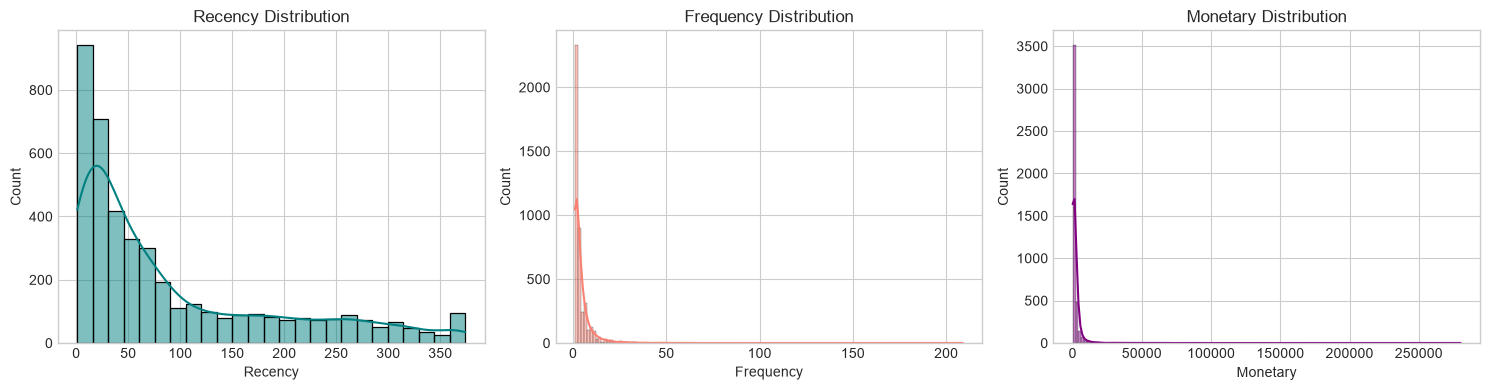

In [ ]:
print("Skewness values:")
print(rfm[['Recency', 'Frequency', 'Monetary']].skew())

# Visualize the raw distributions
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(rfm['Recency'], kde=True, ax=axes[0], color='teal')
axes[0].set_title('Recency Distribution')

sns.histplot(rfm['Frequency'], kde=True, ax=axes[1], color='salmon')
axes[1].set_title('Frequency Distribution')

sns.histplot(rfm['Monetary'], kde=True, ax=axes[2], color='purple')
axes[2].set_title('Monetary Distribution')

plt.tight_layout()
plt.show()

In [ ]:
rfm_log = pd.DataFrame()
rfm_log['Customer ID'] = rfm['Customer ID']

rfm_log['Recency'] = np.log(rfm['Recency'] + 1)
rfm_log['Frequency'] = np.log(rfm['Frequency'])
rfm_log['Monetary'] = np.log(rfm['Monetary'])

rfm_log.head()

,Customer ID,Recency,Frequency,Monetary
0,12346,5.789960,0.000000,11.253942
1,12347,1.098612,1.945910,8.368693
2,12348,4.330733,1.386294,7.494007
3,12349,2.995732,0.000000,7.471676
4,12350,5.739793,0.000000,5.812338


In [ ]:
# Check skewness before vs after
print("Original Skewness:")
print(rfm[['Recency', 'Frequency', 'Monetary']].skew().round(2))
print("\nLog-Transformed Skewness:")
print(rfm_log[['Recency', 'Frequency', 'Monetary']].skew().round(2))

--- Skewness Comparison ---
Original Skewness:
Recency       1.25
Frequency    12.07
Monetary     19.34
dtype: float64

Log-Transformed Skewness:
Recency     -0.38
Frequency    0.78
Monetary     0.38
dtype: float64


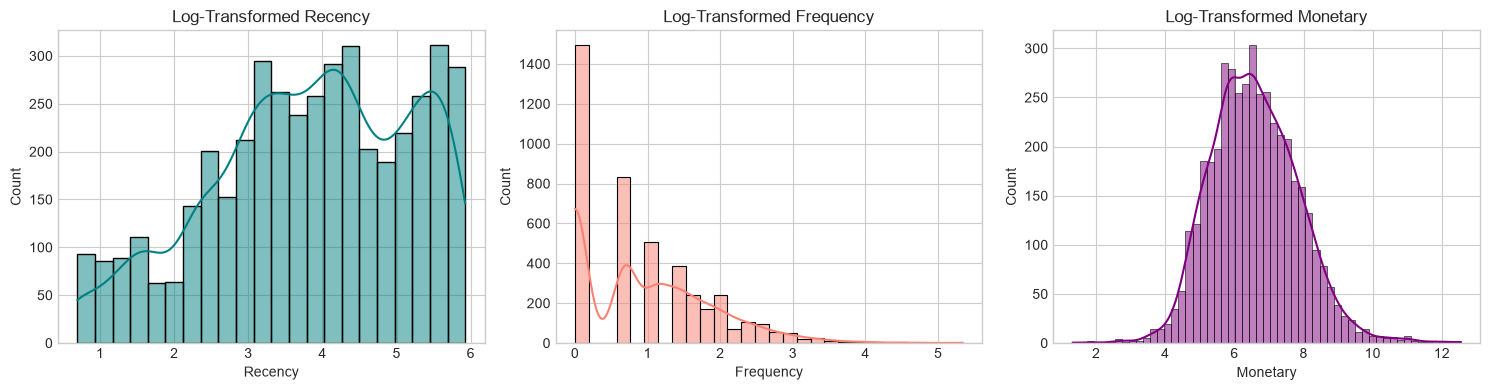

In [ ]:
# newly normalized distributions
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(rfm_log['Recency'], kde=True, ax=axes[0], color='teal')
axes[0].set_title('Log-Transformed Recency')

sns.histplot(rfm_log['Frequency'], kde=True, ax=axes[1], color='salmon')
axes[1].set_title('Log-Transformed Frequency')

sns.histplot(rfm_log['Monetary'], kde=True, ax=axes[2], color='purple')
axes[2].set_title('Log-Transformed Monetary')

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.preprocessing import StandardScaler

features = ['Recency', 'Frequency', 'Monetary']
X = rfm_log[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(X_scaled, columns=features)

X_scaled_df.head()

,Recency,Frequency,Monetary
0,1.461993,-1.048610,3.700195
1,-2.038734,1.111836,1.413252
2,0.373104,0.490522,0.719947
3,-0.623086,-1.048610,0.702247
4,1.424558,-1.048610,-0.612999


In [ ]:
# Verify mean and std_deviation
X_scaled_df.describe().round(2)

,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,-0.00,-0.00,0.00
std,1.00,1.00,1.00
min,-2.34,-1.05,-4.17
25%,-0.66,-1.05,-0.68
50%,0.09,-0.28,-0.06
75%,0.84,0.74,0.66
max,1.56,4.88,4.72


In [123]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia_list = []
silhouette_list = []
k_range = range(2, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', max_iter=300, random_state=42)
    kmeans.fit(X_scaled)
    
    inertia_list.append(kmeans.inertia_)
    
    score = silhouette_score(X_scaled, kmeans.labels_)
    silhouette_list.append(score)
    print(f"k = {k} | Inertia = {kmeans.inertia_:.2f} | Silhouette Score = {score:.4f}")

k = 2 | Inertia = 6375.20 | Silhouette Score = 0.4308
k = 3 | Inertia = 4836.97 | Silhouette Score = 0.3329
k = 4 | Inertia = 3908.17 | Silhouette Score = 0.3311
k = 5 | Inertia = 3316.00 | Silhouette Score = 0.3101
k = 6 | Inertia = 2860.77 | Silhouette Score = 0.3117
k = 7 | Inertia = 2560.33 | Silhouette Score = 0.3106
k = 8 | Inertia = 2354.69 | Silhouette Score = 0.2786
k = 9 | Inertia = 2167.22 | Silhouette Score = 0.2812
k = 10 | Inertia = 2032.73 | Silhouette Score = 0.2772


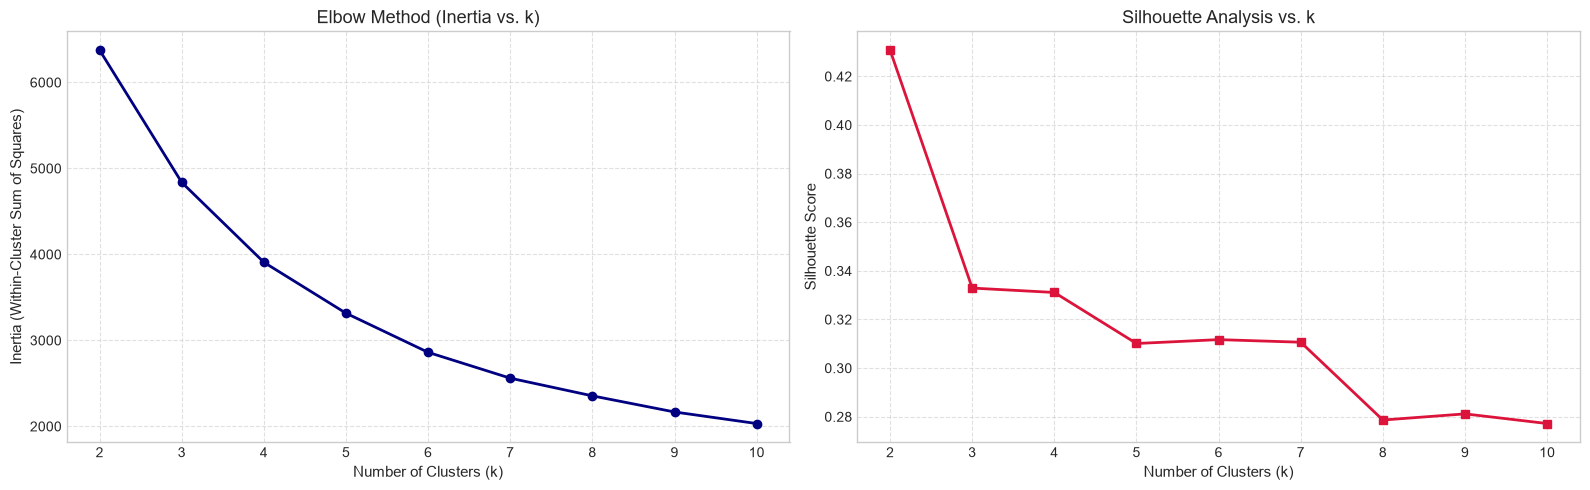

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# 1. Elbow Method plot
ax1.plot(list(k_range), inertia_list, marker='o', linewidth=2, color='navy')
ax1.set_title('Elbow Method (Inertia vs. k)', fontsize=13)
ax1.set_xlabel('Number of Clusters (k)', fontsize=11)
ax1.set_ylabel('Inertia (Within-Cluster Sum of Squares)', fontsize=11)
ax1.set_xticks(list(k_range))
ax1.grid(True, linestyle='--', alpha=0.6)

# 2. Silhouette Score plot
ax2.plot(list(k_range), silhouette_list, marker='s', linewidth=2, color='crimson')
ax2.set_title('Silhouette Analysis vs. k', fontsize=13)
ax2.set_xlabel('Number of Clusters (k)', fontsize=11)
ax2.set_ylabel('Silhouette Score', fontsize=11)
ax2.set_xticks(list(k_range))
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

In [ ]:
metrics_df = pd.DataFrame({
    'k': list(k_range),
    'Inertia': inertia_list,
    'Silhouette_Score': silhouette_list
})

metrics_df.round(4)


,k,Inertia,Silhouette_Score
0,2,6375.1988,0.4308
1,3,4836.9715,0.3329
2,4,3908.1706,0.3311
3,5,3316.0017,0.3101
4,6,2860.7688,0.3117
5,7,2560.3290,0.3106
6,8,2354.6852,0.2786
7,9,2167.2235,0.2812
8,10,2032.7251,0.2772


In [ ]:
optimal_k = 3

kmeans_final = KMeans(n_clusters=optimal_k, init='k-means++', max_iter=300, random_state=42)
kmeans_final.fit(X_scaled)

rfm['Cluster'] = kmeans_final.labels_

print("Customer counts per cluster:")
print(rfm['Cluster'].value_counts().sort_index())
rfm.head()

Customer counts per cluster:
Cluster
0    1662
1     862
2    1814
Name: count, dtype: int64


,Customer ID,Recency,Frequency,Monetary,Cluster,Segment
0,12346,326,1,77183.60,0,Dormant / At Risk
1,12347,2,7,4310.00,1,Potential Loyalists
2,12348,75,4,1797.24,0,Dormant / At Risk
3,12349,19,1,1757.55,0,Dormant / At Risk
4,12350,310,1,334.40,2,Champions / VIPs


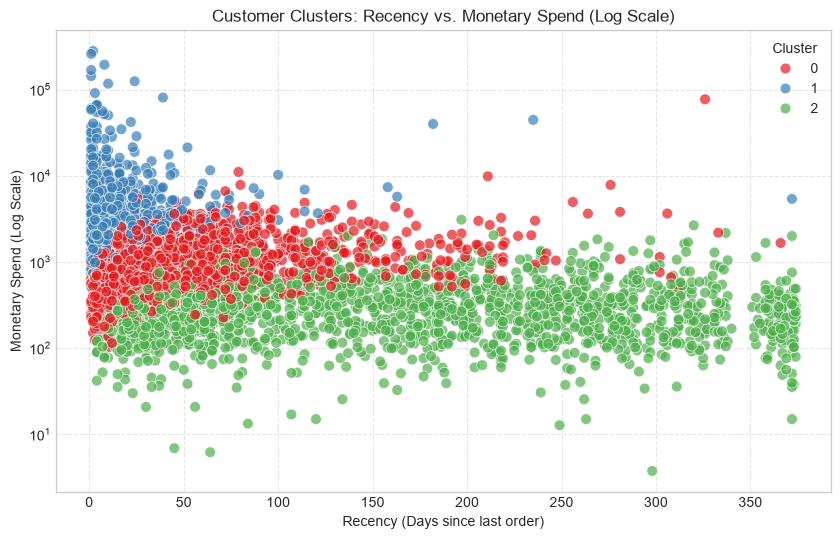

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=rfm,
    x='Recency',
    y='Monetary',
    hue='Cluster',
    palette='Set1',
    alpha=0.7,
    s=60
)
plt.yscale('log') 
plt.title('Customer Clusters: Recency vs. Monetary Spend (Log Scale)')
plt.xlabel('Recency (Days since last order)')
plt.ylabel('Monetary Spend (Log Scale)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [ ]:
cluster_summary = rfm.groupby('Cluster').agg({
    'Recency': ['mean', 'median'],
    'Frequency': ['mean', 'median'],
    'Monetary': ['mean', 'median', 'sum'],
    'Customer ID': 'count'
}).round(1)

cluster_summary.columns = [
    'Recency_Mean', 'Recency_Median',
    'Frequency_Mean', 'Frequency_Median',
    'Monetary_Mean', 'Monetary_Median',
    'Total_Revenue', 'Customer_Count'
]

cluster_summary['Customer_Pct'] = (cluster_summary['Customer_Count'] / cluster_summary['Customer_Count'].sum() * 100).round(1)
cluster_summary['Revenue_Pct'] = (cluster_summary['Total_Revenue'] / cluster_summary['Total_Revenue'].sum() * 100).round(1)

cluster_summary[['Customer_Count', 'Customer_Pct', 'Total_Revenue', 'Revenue_Pct', 'Recency_Mean', 'Frequency_Mean', 'Monetary_Mean']]

,Customer_Count,Customer_Pct,Total_Revenue,Revenue_Pct,Recency_Mean,Frequency_Mean,Monetary_Mean
Cluster,,,,,,,
0,1662,38.3,2021114.2,22.7,53.1,3.3,1216.1
1,862,19.9,6248235.2,70.3,15.5,12.4,7248.5
2,1814,41.8,617877.4,7.0,165.3,1.3,340.6


In [ ]:
cluster_labels = {
    0: 'Dormant / At Risk',
    1: 'Potential Loyalists',
    2: 'Champions / VIPs'
}
rfm['Segment'] = rfm['Cluster'].map(cluster_labels)

rfm[['Customer ID', 'Recency', 'Frequency', 'Monetary', 'Segment']].head(10)

,Customer ID,Recency,Frequency,Monetary,Segment
0,12346,326,1,77183.60,Dormant / At Risk
1,12347,2,7,4310.00,Potential Loyalists
2,12348,75,4,1797.24,Dormant / At Risk
3,12349,19,1,1757.55,Dormant / At Risk
4,12350,310,1,334.40,Champions / VIPs
5,12352,36,8,2506.04,Potential Loyalists
6,12353,204,1,89.00,Champions / VIPs
7,12354,232,1,1079.40,Champions / VIPs
8,12355,214,1,459.40,Champions / VIPs
9,12356,23,3,2811.43,Dormant / At Risk


In [125]:
final_export = rfm[['Customer ID', 'Recency', 'Frequency', 'Monetary', 'Cluster', 'Segment']]

final_export.to_csv('ecommerce_customer_segments.csv', index=False)

print(f"Successfully exported {len(final_export)} customer records to 'ecommerce_customer_segments.csv'")
final_export.head()

Successfully exported 4338 customer records to 'ecommerce_customer_segments.csv'


,Customer ID,Recency,Frequency,Monetary,Cluster,Segment
0,12346,326,1,77183.60,0,Dormant / At Risk
1,12347,2,7,4310.00,1,Potential Loyalists
2,12348,75,4,1797.24,0,Dormant / At Risk
3,12349,19,1,1757.55,0,Dormant / At Risk
4,12350,310,1,334.40,2,Champions / VIPs
